<div style="background: linear-gradient(135deg, #4a0f24 0%, #8e2a4f 100%); color: #ffffff; text-align: center; padding: 50px 30px; border-radius: 14px; box-shadow: 0 6px 18px rgba(0,0,0,0.25); margin: 10px auto; max-width: 900px;">

<div style="font-size: 0.9em; letter-spacing: 4px; text-transform: uppercase; opacity: 0.8; margin-bottom: 12px;">Projet . Machine Learning 1</div>

<div style="font-size: 2.6em; font-weight: 700; line-height: 1.15; margin-bottom: 14px;"> 🍷 Classification de la qualité du vin</div>

<div style="width: 80px; height: 3px; background: #ffffff; opacity: 0.6; margin: 0 auto 22px auto; border-radius: 2px;"></div>

<div style="font-size: 1.25em; font-weight: 600;">Mohamed Amine Rahmouni</div>

<div style="font-size: 0.95em; opacity: 0.8; margin-top: 6px;">EFREI · 2026-2027 · Octobre 2026</div>

</div>

L'objectif est de prédire si un vin est **« bon »** (note ≥ 7) à partir de 11 mesures physico-chimiques, par classification supervisée. Les données sont le jeu *Wine Quality* de l'UCI (Cortez et al., 2009) : vins rouges et blancs du Vinho Verde, soit 6497 observations (5320 après suppression des doublons).

##  Préparation des données
- Fusion des vins rouges et blancs, ajout de la variable `type` (encodée en `type_white`).
- Suppression de 1177 doublons pour éviter la fuite de données entre entraînement et test.
- Aucune valeur manquante ; valeurs extrêmes conservées (plausibles chimiquement).
- Cible binaire : `quality ≥ 7`. **Classes déséquilibrées : 19 % de bons vins.**
- Découpage 80/20 stratifié (4256 observations d'entraînement, 1064 de test) ; standardisation et sélection de variables placées **dans un Pipeline** pour éviter toute fuite.
- Sélection de variables : filtre de Pearson (seuil 0,03, qui n'écarte que `free sulfur dioxide`) pour les modèles de base, et `SelectKBest` (k optimisé par validation croisée) pour les modèles optimisés.

##  Méthode
**Au total y'en a 7 models** sont comparés : régression logistique, k-NN, arbre de décision, Naive Bayes, SVM (noyau RBF). Deux **modèles complémentaires** non linéaires (Random Forest et Gradient Boosting) sont ajoutés pour vérifier si les modèles imposés atteignent un plafond. Hyperparamètres optimisés par **Grid Search** et **Random Search** avec validation croisée stratifiée à 5 plis, critère **F1**. Les trois meilleurs modèles sont ensuite comparés par validation croisée répétée (5×5).

##  Résultats (jeu de test, modèles optimisés)

| Modèle | Précision | Rappel | F1 | AUC | F1 en validation croisée | Écart F1 train-test |
|---|---|---|---|---|---|---|
| Régression logistique | 0,400 | 0,797 | 0,533 | 0,817 | 0,539 ± 0,020 | 0,007 |
| k-NN | **0,628** | 0,460 | 0,531 | 0,824 | 0,492 ± 0,023 | 0,469 |
| Arbre de décision | 0,366 | 0,733 | 0,488 | 0,784 | 0,515 ± 0,018 | 0,037 |
| Naive Bayes | 0,381 | 0,584 | 0,461 | 0,761 | 0,500 ± 0,011 | 0,037 |
| **SVM (RBF)** | 0,405 | **0,827** | 0,544 | 0,854 | 0,546 ± 0,011 | 0,041 |
| Random Forest *(complément)* | 0,561 | 0,634 | **0,595** | **0,872** | **0,562 ± 0,025** | 0,268 |
| Gradient Boosting *(complément)* | 0,476 | 0,777 | 0,590 | 0,867 | 0,551 ± 0,014 | 0,121 |

**Modèle retenu :SVM à noyau RBF (C = 1, γ = 0,1, seuil de décision 0,361).**

Après optimisation du seuil, trois modèles obtiennent des scores très proches en validation croisée : SVM (F1 = 0,567), Random Forest (0,566) et Gradient Boosting (0,553). Les écarts sont trop faibles pour désigner un vainqueur sur la performance seule.

Nous les départageons donc par leur stabilité. Le SVM surapprend peu : son F1 passe de 0,59 à l’entraînement à 0,57 en test, alors que le Random Forest passe de 0,86 à 0,62, ce qui montre qu’il apprend en partie les données d’entraînement par cœur. Ses résultats varient aussi deux fois moins d’un pli de validation à l’autre.

Le Random Forest fait un peu mieux sur le jeu de test (0,62 contre 0,57). Mais ce jeu ne contient que 202 bons vins, et cet écart n’est pas confirmé en validation croisée. Nous gardons donc la règle fixée au départ : le modèle se choisit en validation croisée, le test sert seulement à confirmer.

##  Observations clés
- L'accuracy est trompeuse : le k-NN atteint 0,846 mais ne retrouve que 46 % des bons vins.
- Le k-NN surapprend fortement (F1 train 1,000 contre 0,531 en test), et le Random Forest aussi, dans une moindre mesure (0,863 contre 0,595).
- Les modèles d'ensemble (Random Forest, Gradient Boosting) font un peu mieux sur le jeu de test, mais pas de façon significative en validation croisée répétée.
- Les variables les plus liées à la qualité sont l'alcool, la densité, les chlorures et l'acidité volatile.
- La standardisation est déterminante : F1 du SVM de 0,416 à 0,545, du k-NN de 0,281 à 0,477.
- Le filtre de Pearson apporte peu : les meilleurs modèles gardent 11 à 12 variables avec `SelectKBest`.

## Lancer le projet
```bash
git clone <URL-du-dépôt>
cd <nom-du-dépôt>
python -m venv venv
source venv/bin/activate        # Windows : venv\Scripts\activate
pip install -r requirements.txt
jupyter notebook projet_vin.ipynb
```

##  Tests
```bash
python -m pytest -v tests/                          # tests unitaires
python -m pytest --nbmake projet_vin.ipynb          # exécute le notebook en entier
```

## 📁 Structure du dépôt
```
├── projet_vin.ipynb        # notebook principal
├── wine.py                 # fonctions réutilisables (préparation, split, pipeline)
├── tests/test_wine.py      # tests unitaires
├── winequality-red.csv     # données (UCI)
├── winequality-white.csv
├── requirements.txt
├── pytest.ini
└── README.md
```

## 📚 Outils
Python 3.9, pandas, NumPy, scikit-learn, SciPy, Matplotlib, Seaborn, pytest, nbmake. Données : UCI Machine Learning Repository.

## Mini-glossaire

### Les bases

| Terme | Explication simple |
|---|---|
| **Variable explicative** (*feature*) | Une mesure qui sert à prédire (ex. le taux d'alcool). |
| **Cible** (*target*) | Ce qu'on veut prédire : ici « bon vin » (1) ou non (0). |
| **Jeu d'entraînement** | Les exemples avec lesquels le modèle apprend (80 %). |
| **Jeu de test** | Des exemples mis de côté, utilisés **une seule fois** à la fin pour vérifier que le modèle sait généraliser (20 %). |
| **Surapprentissage** | Le modèle apprend les exemples « par cœur » (y compris leur bruit) et se trompe sur de nouveaux vins. |
| **Fuite de données** | Une information du jeu de test « s'infiltre » dans l'entraînement, ce qui rend les scores trop beaux pour être vrais. |
| **Classes déséquilibrées** | Une catégorie est beaucoup plus rare que l'autre (19 % de bons vins contre 81 %). |
| **Valeur aberrante** (*outlier*) | Une mesure très éloignée des autres (ex. un vin à 65 g/L de sucre). Ici, elles sont conservées car plausibles. |
| **Corrélation de Pearson** | Un nombre entre −1 et 1 qui mesure le lien **linéaire** entre deux variables. Elle ne détecte pas les relations non linéaires. |

### Préparation et réglage

| Terme | Explication simple |
|---|---|
| **Standardisation** | Mettre toutes les variables à la même échelle (moyenne 0, écart-type 1). |
| **Pipeline** | Une chaîne d'étapes (standardiser, sélectionner, prédire) appliquée de façon identique et sans fuite. |
| **Sélection de variables** | Ne garder que les variables utiles pour réduire le bruit. Ici : un filtre sur la corrélation, puis `SelectKBest` (garde les *k* meilleures variables). |
| **Paramètre / hyperparamètre** | Un *paramètre* est appris par le modèle (ex. un coefficient). Un *hyperparamètre* est un réglage choisi avant l'apprentissage (ex. le nombre de voisins $k$). |
| **Validation croisée** | On découpe l'entraînement en 5 parties, on s'entraîne sur 4 et on teste sur la 5e, en tournant. *Stratifiée* : chaque partie garde la même proportion de bons vins. |
| **Grid Search** | On teste **toutes** les combinaisons d'hyperparamètres d'une grille. Exhaustif mais coûteux. |
| **Random Search** | On teste des combinaisons **tirées au hasard**. Plus rapide, et souvent presque aussi bon. |
| **Pondération des classes** (`class_weight`) | Une erreur sur un bon vin (rare) compte plus qu'une erreur sur un vin ordinaire, pour compenser le déséquilibre. |
| **Modèle d'ensemble** | Un modèle qui combine plusieurs arbres (Random Forest, Gradient Boosting), souvent plus puissant mais plus complexe. |

### Évaluation

| Terme | Explication simple |
|---|---|
| **Accuracy** | Part de prédictions correctes. Trompeuse ici : dire « jamais bon » donnerait déjà 81 %. |
| **Précision** | Parmi les vins annoncés « bons », la part qui l'est vraiment. |
| **Rappel** | Parmi les vrais bons vins, la part que le modèle retrouve. |
| **F1** | Moyenne harmonique de la précision et du rappel : elle est basse dès que l'un des deux l'est. C'est notre critère principal. |
| **Faux positif / faux négatif** | Un vin ordinaire annoncé « bon » / un bon vin raté. |
| **Matrice de confusion** | Un tableau qui compte les vrais et faux positifs et négatifs. |
| **Courbe ROC et AUC** | La courbe compare les bons vins retrouvés aux faux positifs, selon le seuil. L'AUC la résume : 0,5 = hasard, 1 = parfait. |
| **Seuil de décision** | Le niveau de confiance à partir duquel le modèle dit « bon vin » (0,5 par défaut). Le baisser augmente le rappel mais réduit la précision. |
| **Biais / variance** | Un modèle à **biais** élevé est trop simple et rate la structure des données. Un modèle à **variance** élevée est trop souple et colle au bruit (surapprentissage). On cherche un compromis. |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

import pandas as pd, numpy as np, sklearn, matplotlib
import seaborn as sns
import matplotlib.pyplot as plt
print("Tout est OK, sklearn", sklearn.__version__)

Tout est OK, sklearn 1.6.1


lit les deux fichiers CSV ( vin blanc et vin rouge), avec ; comme séparateur parce que c’est le format de l’UCI. Il ajoute une colonne type à chacun, puis les empile l’un sous l’autre avec concat. ignore_index=True renumérote les lignes de 0 à 6496, sinon on aurait deux fois les index 0, 1, 2…

Après la fusion, on ne pourrait plus savoir d’où vient chaque vin. Or les rouges et les blancs ont une chimie différente : le modèle doit pouvoir en tenir compte.

In [2]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["type"] = "red"
white["type"] = "white"
df = pd.concat([red, white], ignore_index=True)

print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


### 2. Contrôle de la qualité des données
info() donne les types et le nombre de valeurs non nulles. isna().sum() compte les valeurs manquantes par colonne. duplicated().sum() compte les lignes identiques à une ligne déjà vue. describe() donne la moyenne, l’écart-type, les quartiles et les extrêmes.

Concrètement: Les écarts entre le 75e percentile et le maximum. Par exemple, le sucre résiduel a un 3e quartile à 7,5 mais un maximum à 65,8 : il y a des valeurs extrêmes, et les variables ont des échelles très différentes.

In [3]:
print("5 premiers vins rouges :")  
display(df[df["type"] == "red"].head())
print("5 premiers vins blancs :")
display(df[df["type"] == "white"].head())
df.info()
print("Valeurs manquantes :")
print(df.isna().sum())

print("Nombre de doublons :", df.duplicated().sum())
display(df.describe().T)
print("Dimensions du dataset :", df.shape)


5 premiers vins rouges :


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


5 premiers vins blancs :


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
1599,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1600,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
1601,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
1602,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
1603,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
Valeurs manquantes :
fixed acidity           0
volatile acidity

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Dimensions du dataset : (6497, 13)


### 3. Suppression des doublons

On supprime toute ligne identique à une ligne précédente, sur toutes les colonnes, y compris la note et le type. Il garde la première occurrence. reset_index(drop=True) renumérote proprement sans garder l’ancien index en colonne.

Le principe de l’indépendance entre entraînement et test. Le test doit simuler des vins jamais vus. Si un vin est en double et qu’une copie tombe dans l’entraînement et l’autre dans le test, le modèle a déjà vu la réponse : c’est une fuite de données, et le score est surestimé.

on applique la suppresion des dbl ici Parce que c’est le découpage qui risque de séparer les copies. Une fois le découpage fait, il est trop tard.

In [4]:
print("Avant :", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Après :", df.shape)

Avant : (6497, 13)
Après : (5320, 13)


In [5]:
df.info()
print("Valeurs manquantes :\n", df.isna().sum())
print("Doublons :", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  type                  5320 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 540.4+ KB
Valeurs manquantes :
 fixed acidity           0
volatile acidit

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


### 4. Détection des valeurs aberrantes

On a détecté les valeurs extrêmes avec la règle de Tukey, c’est-à-dire en dehors de 1,5 fois l’écart interquartile. On les a gardées, parce qu’elles sont chimiquement possibles, par exemple des vins très sucrés, et pas des erreurs de mesure. En contrepartie, on a standardisé les données pour les modèles sensibles aux échelles. 

Q1 et Q3 sont les quartiles : 25 % des valeurs snt sous Q1, 75 % sous Q3. L’IQR, c’est Q3 − Q1, l’étendue des 50 % centraux. Une valeur est aberrante si elle est à plus de 1,5 IQR sous Q1 ou au-dessus de Q3. Le mask est un vecteur de vrai/faux, et .sum() compte les vrais.

on utilise la methode Tukey plutôt que le z-score , Le z-score utilise la moyenne et l’écart-type, qui sont eux-mêmes tirés par les valeurs extrêmes. Les quartiles, eux, ne bougent presque pas : la méthode est robuste.

on les a seulement comptées. Elles sont chimiquement plausibles, et les supprimer ferait perdre de vrais vins.

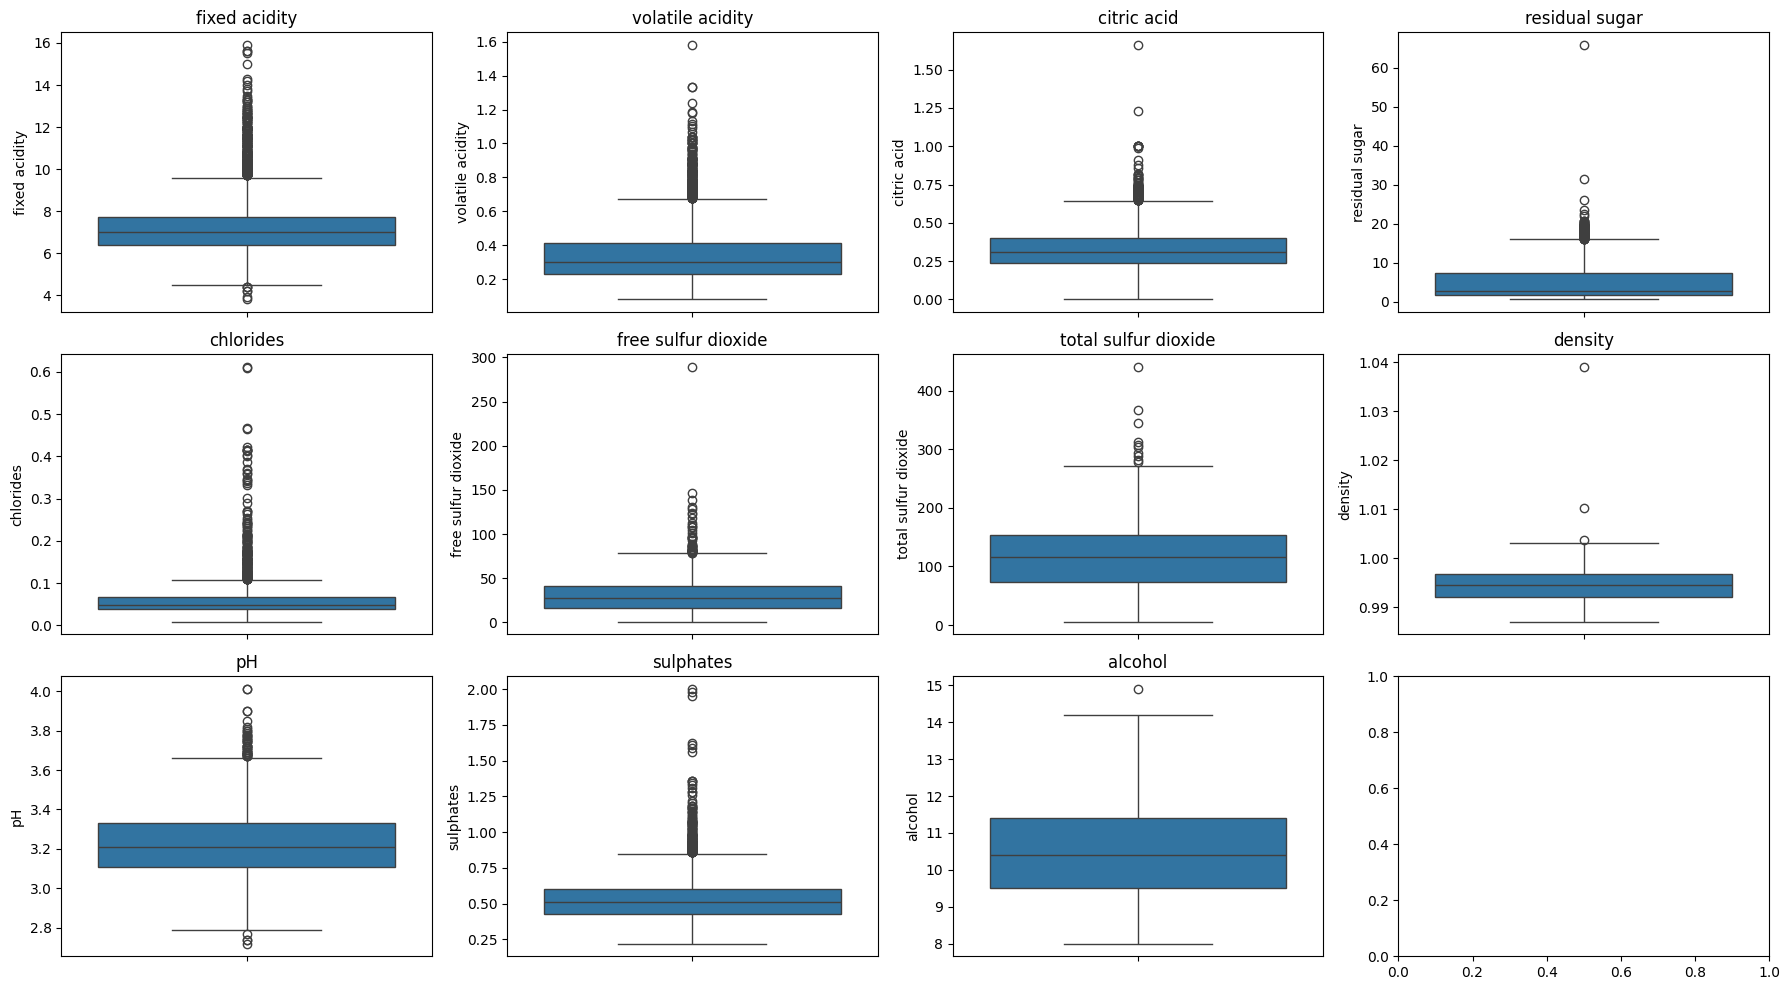

In [6]:
features = df.drop(columns=["quality", "type"]).columns

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Pour chaque variable, on calcule Q1, Q3 et l’IQR = Q3 − Q1. Il compte ensuite les vins qui sortent de l’intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]. Enfin, sort_values(ascending=False) trie les variables de celle qui en a le plus à celle qui en a le moins.

In [7]:
outliers = {}
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    outliers[col] = mask.sum()

pd.Series(outliers).sort_values(ascending=False).to_frame("nb_outliers")


,nb_outliers
fixed acidity,304
volatile acidity,279
chlorides,237
sulphates,163
citric acid,143
residual sugar,141
pH,49
free sulfur dioxide,44
total sulfur dioxide,10
density,3


### 5. Encodage et définition de la cible
df["type"] == "white" donne vrai/faux, et .astype(int) le transforme en 1/0. C’est un encodage binaire.

Avec deux modalités, une seule colonne suffit : si type_white = 0, c’est un rouge. Deux colonnes seraient redondantes, puisque leur somme fait toujours 1, ce qui gêne la régression logistique.

 le value_counts(normalize=True)donne les proportions : 81 % de 0 et 19 % de 1. C’est ce qui révèle le déséquilibre.


good
0    4311
1    1009
Name: count, dtype: int64
good
0    0.81
1    0.19
Name: proportion, dtype: float64


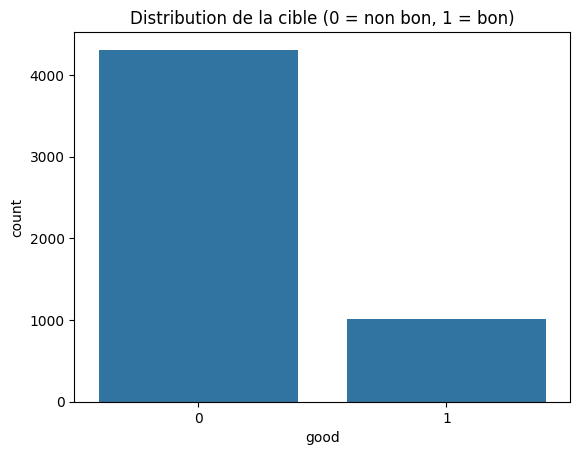

In [8]:
df["type_white"] = (df["type"] == "white").astype(int)
df["good"] = (df["quality"] >= 7).astype(int)

print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

sns.countplot(x="good", data=df)
plt.title("Distribution de la cible (0 = non bon, 1 = bon)")
plt.show()

### 6. Analyse exploratoire
**Distributions.** Les histogrammes permettent d'évaluer l'asymétrie ($\gamma_1$) et la multimodalité des variables, ce qui conditionne la pertinence des hypothèses paramétriques (loi normale conditionnelle de Naive Bayes).


**Corrélations.** Le coefficient de Pearson mesure la dépendance linéaire entre deux variables ; avec la cible binaire, il correspond au coefficient point-bisérial. Il permet de (i) identifier les variables informatives et (ii) détecter la **multicolinéarité** (ex. `free`/`total sulfur dioxide` : 0,72 ; `alcohol`/`density` : −0,67), qui déstabilise l'estimation des coefficients des modèles linéaires.
**Limite.** Le coefficient de Pearson ne capte pas les relations non linéaires ; une variable faiblement corrélée peut rester utile à un modèle non linéaire.

quality est la variable d’où vient la cible. Ici, on étudie les variables explicatives, celles qui servent à prédire. La cible est analysée à part, avec le graphique de distribution des classes (19 % de bons vins). »


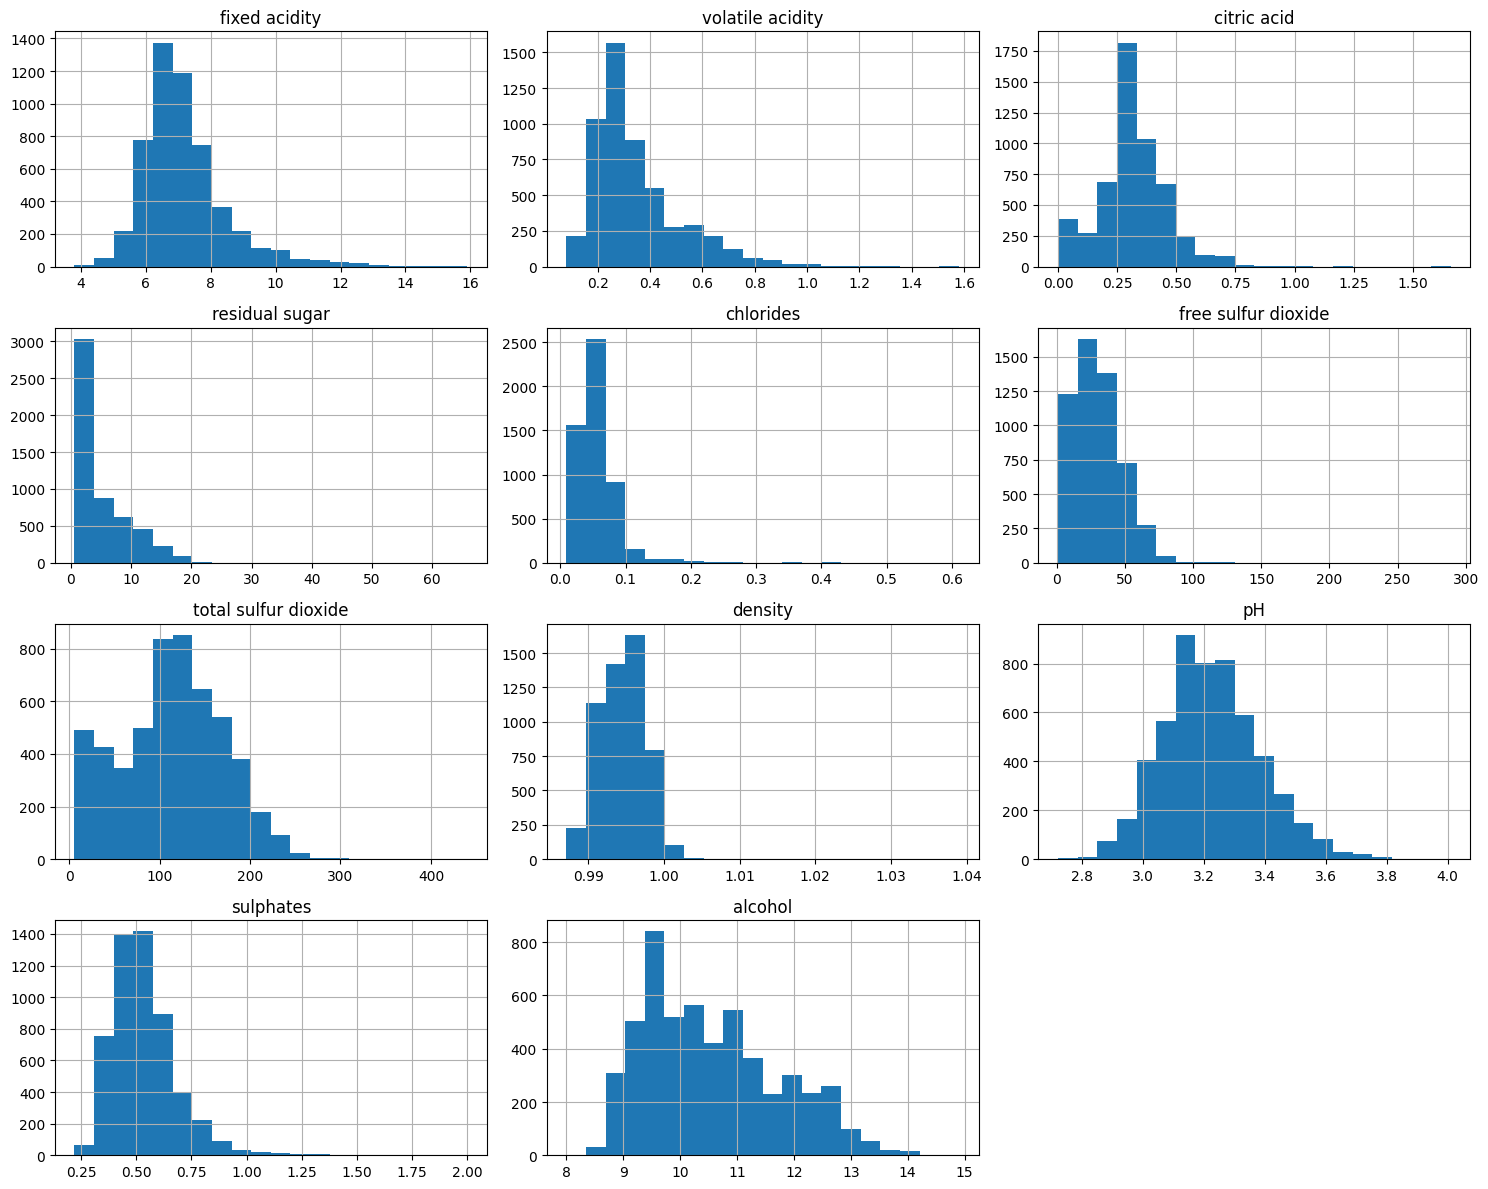

In [9]:
# Histogrammes des variables numériques

features = df.drop(columns=["quality", "type", "good", "type_white"]).columns
df[features].hist(figsize=(15, 12), bins=20)    
plt.tight_layout()
plt.show()

### 6.2 Matrice de corrélation


**Comment lire la matrice.** Rouge : les deux variables varient dans le même sens (r > 0). Bleu : elles varient en sens inverse (r < 0). Plus la couleur est foncée, plus le lien est fort ; proche de 0 (blanc), il n'y a pas de lien linéaire.

#### Ce que l'on observe

**1. Liens avec la cible (« bon vin »).**

| Variable | r avec `good` | Lecture |
|---|---|---|
| `alcohol` | **+0,42** | Plus un vin est alcoolisé, plus il est souvent jugé bon |
| `density` | **−0,29** | Les vins moins denses sont plus souvent bons |
| `chlorides` | −0,16 | Effet négatif modeste |
| `volatile acidity` | −0,14 | Effet négatif modeste (acidité volatile élevée = défaut de goût) |
| `residual sugar`, `total sulfur dioxide`, `fixed acidity` | −0,09 à −0,05 | Quasi nul |
| `type_white`, `citric acid`, `pH`, `sulphates`, `free sulfur dioxide` | +0,08 à +0,01 | Quasi nul |

Une seule variable ressort nettement (`alcohol`). Même elle n'explique qu'environ 17 % de la variance de la cible de façon linéaire (0,42² ≈ 0,17). Aucune variable ne suffit à prédire la qualité : cela **annonce un problème difficile**, ce que confirment les F1 d'environ 0,55 obtenus plus loin.

**2. Redondances entre variables explicatives.**

| Paire | r | Explication probable |
|---|---|---|
| `free` / `total sulfur dioxide` | +0,72 | Le SO₂ libre est une partie du SO₂ total |
| `alcohol` / `density` | −0,67 | L'alcool est moins dense que l'eau : plus d'alcool, densité plus faible |
| `total sulfur dioxide` / `type_white` | +0,69 | Les blancs contiennent nettement plus de SO₂ que les rouges |
| `volatile acidity` / `type_white` | −0,65 | Les rouges ont une acidité volatile plus élevée |

Les deux dernières paires viennent du **mélange des vins rouges et blancs** : `type_white` résume à lui seul une partie des différences chimiques entre les deux populations.
 test.

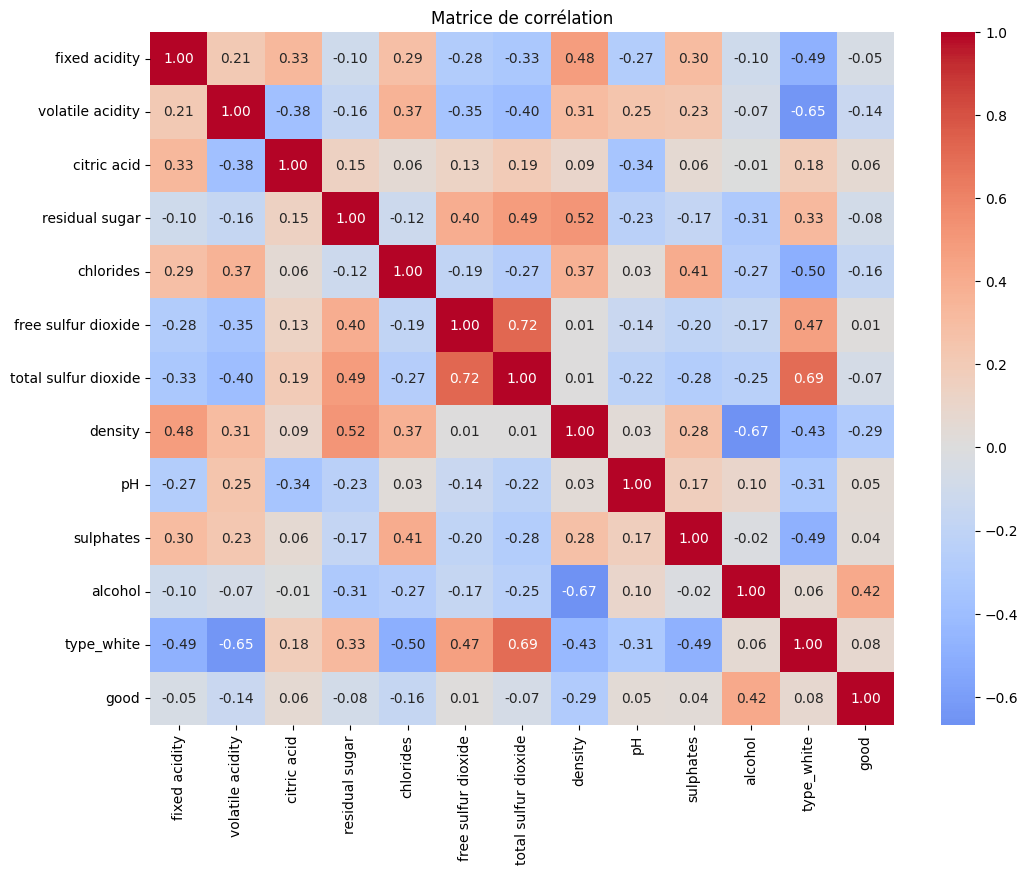

alcohol                 0.417743
type_white              0.081083
citric acid             0.060672
pH                      0.048330
sulphates               0.036771
free sulfur dioxide     0.011325
fixed acidity          -0.049841
total sulfur dioxide   -0.067307
residual sugar         -0.084868
volatile acidity       -0.144361
chlorides              -0.161027
density                -0.294971
Name: good, dtype: float64

In [10]:
cols = list(features) + ["type_white", "good"]
corr = df[cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

corr["good"].drop("good").sort_values(ascending=False)

### 7. Découpage entraînement / test
Dans wine.py on a : train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

le stratify=y garantit que l’entraînement et le test ont la même proportion de bons vins (19 %). Sans lui, le hasard pourrait mettre par exemple 15 % d’un côté et 25 % de l’autre.

Et random_state=42 fixe le hasard pour que le découpage soit identique à chaque exécution. Les résultats sont ainsi reproductibles.

Pourquoi mettre le code dans wine.py, Pour le réutiliser ailleurs (tests unitaires) et le tester séparément.

In [11]:
from wine import prepare, split, make_pipe

X, y = prepare(df)
X_train, X_test, y_train, y_test = split(X, y)

print(X_train.shape, X_test.shape)

(4256, 12) (1064, 12)


calculer la corrélation sur X_train seulement, on la calcule avec le test, on choisit les variables en regardant les réponses du test : c’est une fuite.

.abs() ? Une corrélation de −0,29 (la densité) est aussi informative qu’une de +0,29. Seule la force du lien compte, pas son sens.

on choisi le seuil de 0,03 ? En comparant plusieurs seuils en validation croisée. 
Les modèles font mieux avec plus de variables, donc on a pris le seuil le plus bas : il n’écarte que le SO₂ libre.

In [12]:
# Feature Selection - Méthode Filter avec corrélation de Pearson

train_data = X_train.copy()
train_data["good"] = y_train
corr_train = train_data.corr()
correlations = (
    corr_train["good"]
    .drop("good")
    .abs()
    .sort_values(ascending=False)
)

display(correlations.to_frame("abs_correlation"))

,abs_correlation
alcohol,0.422594
density,0.297680
chlorides,0.158681
volatile acidity,0.142750
residual sugar,0.085749
type_white,0.080539
total sulfur dioxide,0.074100
citric acid,0.058113
fixed acidity,0.042601
pH,0.041527


pourquoi X_train et pas tout df
on a deja calculé une matrice de corrélation sur tout le jeu de données dans l’analyse exploratoire. Ici,le recalcules sur l’entraînement seulement, parce que cette fois elle sert à prendre une décision : choisir les variables.
Si utilisais aussi le test,  on choisit les variables en regardant les réponses du test : ce serait une fuite de données, et le score final serait trop optimiste. 

La règle : l’exploration peut utiliser toutes les données, mais toute décision qui influence le modèle se prend sur l’entraînement 
uniquement.


Corrélation de Pearson avec une variable binaire Oui. Quand une des deux variables est binaire (0/1), la corrélation de Pearson s’appelle le coefficient point-bisérial. Il mesure si la moyenne de la variable est différente entre les bons et les mauvais vins.



In [13]:
threshold = 0.03

selected_features = correlations[
    correlations >= threshold
].index.tolist()

print("Variables sélectionnées :", selected_features)
print("Nombre de variables :", len(selected_features))

Variables sélectionnées : ['alcohol', 'density', 'chlorides', 'volatile acidity', 'residual sugar', 'type_white', 'total sulfur dioxide', 'citric acid', 'fixed acidity', 'pH', 'sulphates']
Nombre de variables : 11


In [14]:
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("X_train :", X_train_selected.shape)
print("X_test :", X_test_selected.shape)

X_train : (4256, 11)
X_test : (1064, 11)


 Standardisation
 
fit apprend la moyenne et l’écart-type, transform les applique : z = (x − moyenne) / écart-type. On apprend sur l’entraînement seulement, puis on applique les mêmes valeurs au test.

Le test représente des données futures, inconnues. On ne peut pas calculer leur moyenne à l’avance. Et si on le faisait, des informations du test entreraient dans le modèle.

Quels modèles en ont besoin// Ceux qui utilisent des distances ou une régularisation : k-NN, SVM, régression logistique. Les arbres non, car ils coupent sur des seuils et l’échelle ne change rien. On l’a vérifié : la standardisation fait passer le SVM de 0,42 à 0,55.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [16]:
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

In [17]:
print(X_train_scaled.mean(axis=0).round(3))
print(X_train_scaled.std(axis=0).round(3))

[ 0.  0.  0.  0.  0. -0.  0.  0.  0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


class_weight=balanced  > Il donne à chaque classe un poids inversement proportionnel à sa fréquence : w = n / (2 × n_classe). Les bons vins pèsent environ 2,6 et les autres environ 0,6. Une erreur sur un bon vin coûte donc environ 4 fois plus cher, ce qui oblige le modèle à s’y intéresser.

balanced_subsample pour le Random Forest > Même principe, mais les poids sont recalculés sur l’échantillon bootstrap de chaque arbre.

Pourquoi max_iter=1000  > La régression logistique est optimisée par un algorithme itératif. Avec 100 itérations, la valeur par défaut, il peut ne pas converger.

Pourquoi le k-NN n’a pas de class_weight <> car Il ne le propose pas : il vote simplement avec ses voisins. C’est une des raisons de son faible rappel.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Régression logistique": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "k-NN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Arbre de décision": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "SVM (RBF)": SVC(
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    )
}

In [19]:
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)

print("Entraînement terminé.")

Entraînement terminé.


### 11. Métriques d'évaluation
Avec 19 % de positifs, l'accuracy est trompeuse. Nous retenons : la **précision** $\frac{TP}{TP+FP}$, le **rappel** $\frac{TP}{TP+FN}$, leur moyenne harmonique le **F1**, et l'**AUC** $=P(s^+>s^-)$, indépendante du seuil de décision. La matrice de confusion détaille la nature des erreurs, la courbe ROC le compromis $TPR$/$FPR$.
**Critère principal.** Le F1 de la classe « bon » : il pénalise un modèle dont la précision ou le rappel est faible.

la condition sur le AUC n’a pas besoin des classes prédites (0/1), mais d’un score continu pour classer les vins. Le SVM n’a pas de probabilités par défaut : il donne une distance à la frontière avec decision_function. Les autres modèles donnent predict_proba, dont on prend la colonne 1, la probabilité d’être bon.

l’AUC est La probabilité qu’un bon vin tiré au hasard ait un score plus élevé qu’un vin ordinaire tiré au hasard. 0,5, c’est le hasard ; 1, c’est parfait. Elle ne dépend pas du seuil.

Précision, rappel, F1 : Précision = VP / (VP + FP), rappel = VP / (VP + FN), et le F1 est leur moyenne harmonique : il est bas dès que l’un des deux l’est.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rows = []

for name, model in models.items():
    y_pred = predictions[name]

    if hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test_scaled)
    else:
        y_score = model.predict_proba(X_test_scaled)[:, 1]

    rows.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred),
        "Rappel": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score)
    })

results = pd.DataFrame(rows).set_index("Modèle").round(3)

display(results)

,Accuracy,Précision,Rappel,F1,AUC
Modèle,,,,,
Régression logistique,0.723,0.385,0.772,0.514,0.815
k-NN,0.830,0.571,0.416,0.481,0.820
Arbre de décision,0.673,0.349,0.832,0.491,0.788
Naive Bayes,0.730,0.376,0.639,0.473,0.759
SVM (RBF),0.718,0.386,0.822,0.525,0.847
Random Forest,0.841,0.677,0.312,0.427,0.869
Gradient Boosting,0.810,0.500,0.668,0.572,0.844


le classification_report est utile car donne les métriques pour chaque classe, plus les moyennes macro (simple moyenne des classes) et pondérée (selon le nombre de vins). Il montre par exemple que tous les modèles reconnaissent bien les vins ordinaires, et que toute la difficulté porte sur les bons.

Où sont les faux négatifs , Dans la matrice de confusion, en bas à gauche : des bons vins prédits « non bons ». Le rappel de la classe « bon » vaut 1 − taux de faux négatifs.

In [21]:
from sklearn.metrics import classification_report

for name in ["SVM (RBF)", "Random Forest", "Gradient Boosting", "Régression logistique"]:
    print(f"===== {name} (modèle de base) =====")
    print(classification_report(y_test, predictions[name],
                                target_names=["non bon (0)", "bon (1)"], digits=3))

===== SVM (RBF) (modèle de base) =====
              precision    recall  f1-score   support

 non bon (0)      0.943     0.694     0.799       862
     bon (1)      0.386     0.822     0.525       202

    accuracy                          0.718      1064
   macro avg      0.665     0.758     0.662      1064
weighted avg      0.837     0.718     0.747      1064

===== Random Forest (modèle de base) =====
              precision    recall  f1-score   support

 non bon (0)      0.857     0.965     0.908       862
     bon (1)      0.677     0.312     0.427       202

    accuracy                          0.841      1064
   macro avg      0.767     0.639     0.667      1064
weighted avg      0.823     0.841     0.817      1064

===== Gradient Boosting (modèle de base) =====
              precision    recall  f1-score   support

 non bon (0)      0.916     0.843     0.878       862
     bon (1)      0.500     0.668     0.572       202

    accuracy                          0.810      1064

Ici, on affiche la matrice de confusion de chaque modèle de base sur le jeu de test. Les lignes représentent la vérité, les colonnes ce que le modèle a prédit : la diagonale correspond aux bonnes réponses, et les deux autres cases aux erreurs. En haut à droite, ce sont les fausses alertes, des vins ordinaires annoncés bons ; en bas à gauche, ce sont les bons vins ratés. On voit tout de suite deux comportements opposés. Le Random Forest ne dit presque jamais « bon » : seulement 30 fausses alertes, mais il rate 139 bons vins sur 202. Le SVM fait l’inverse : il ne rate que 36 bons vins, mais il fait 264 fausses alertes. Aucun des deux n’est équilibré au seuil par défaut. C’est ce qui nous a amenés à optimiser les hyperparamètres, puis le seuil de décision.

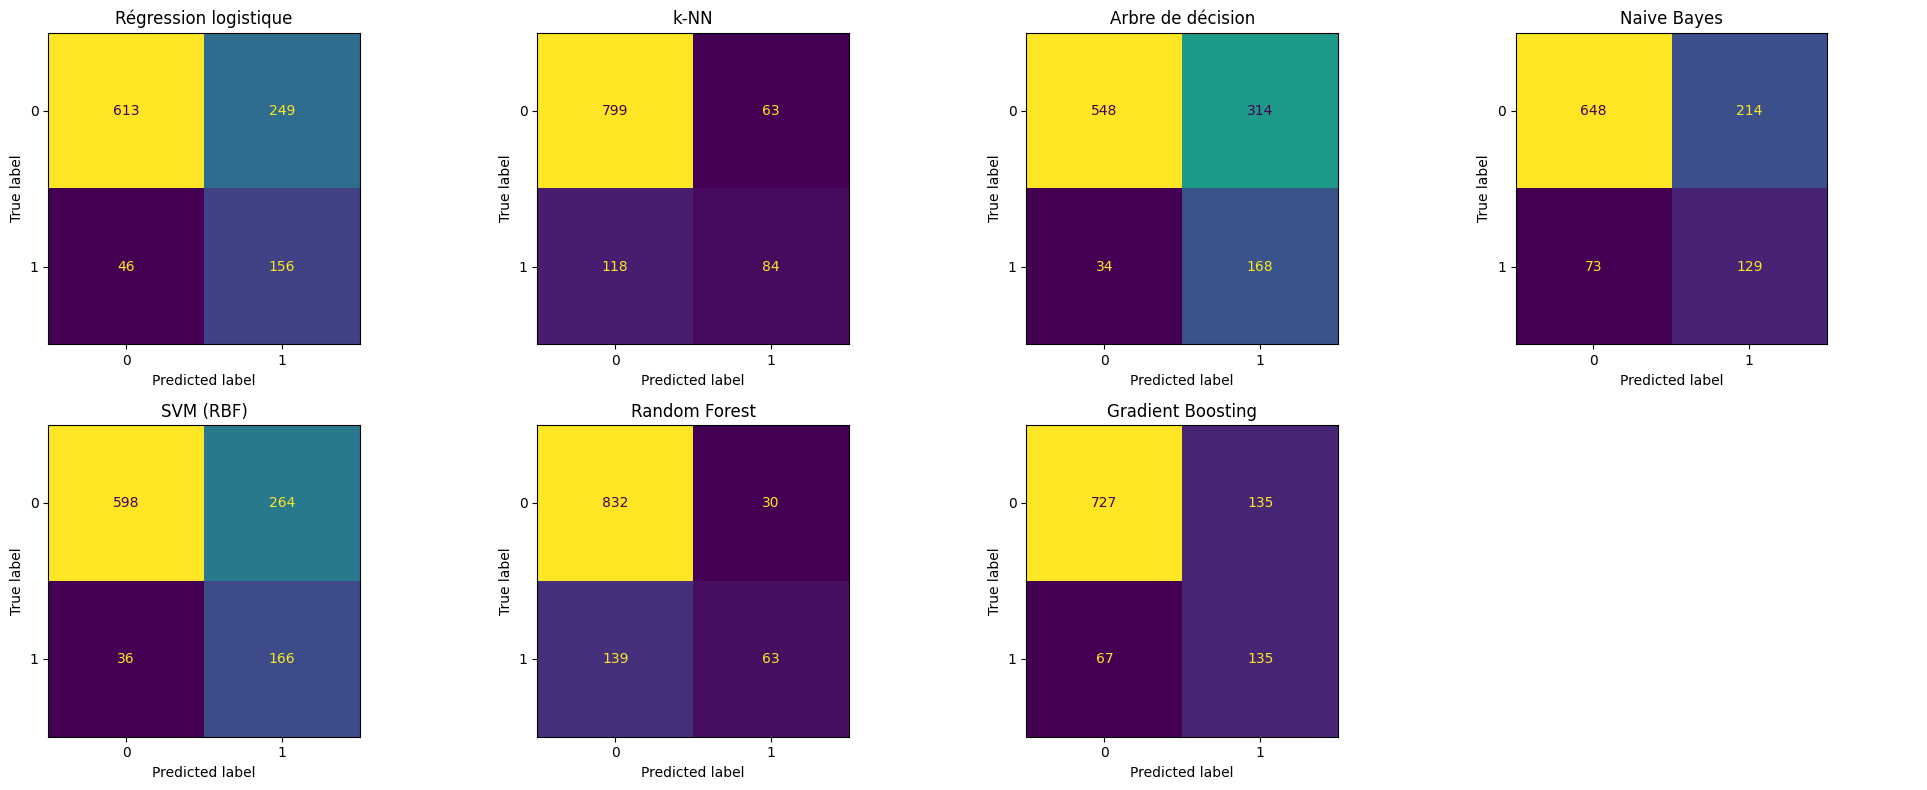

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

n = len(models)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

La courbe ROC montre, pour chaque seuil, la part de bons vins retrouvés en fonction des fausses alertes. Plus la courbe monte vers le coin en haut à gauche, meilleur est le modèle ; la diagonale, c’est le hasard. L’AUC résume la courbe en un nombre. Le Random Forest a la meilleure AUC, 0,87, alors qu’il avait le plus mauvais F1 : il classe bien les vins, mais son seuil par défaut est mal placé. D’où l’intérêt d’optimiser le seuil.

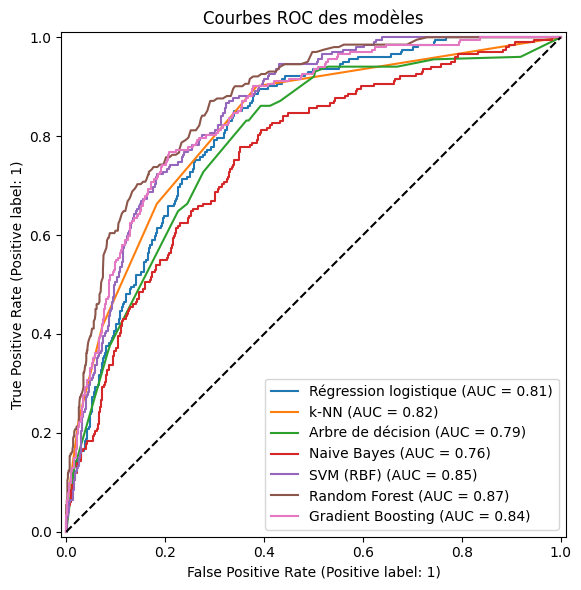

In [23]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test_scaled,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Courbes ROC des modèles")
plt.tight_layout()
plt.show()

### 12. Optimisation des hyperparamètres


principe la validation croisée. On coupe l’entraînement en 5 parties ici n_splits . On entraîne sur 4 et on évalue sur la 5e, puis on recommence 5 fois en changeant la partie d’évaluation. On obtient 5 scores : leur moyenne estime la performance, leur écart-type mesure la stabilité.

shuffle=True pour que Les données sont rangées (les rouges d’abord, puis les blancs). Sans mélange, certains plis ne contiendraient que des rouges.

why le test vers la fin car , Le test ne doit servir qu’une fois, à la fin. Si on règle les modèles en regardant le test, il n’est plus une estimation honnête.

 Pourquoi un pipeline , Dans la validation croisée, la partie d’évaluation joue le rôle du test. Si on standardise avant, la moyenne inclut cette partie : c’est une fuite. Avec le pipeline, à chaque pli, le scaler et le SelectKBest sont refaits sur les 4 parties d’entraînement uniquement.

Que fait SelectKBest(f_classif) ? Pour chaque variable, il fait un test F d’ANOVA : est-ce que la moyenne de la variable diffère entre bons et mauvais vins ? Il garde les k variables avec le F le plus élevé.

Pourquoi select__k dans la grille ? Le double tiret désigne un paramètre d’une étape du pipeline : k de l’étape select. Le nombre de variables devient ainsi un hyperparamètre optimisé comme les autres.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.stats import loguniform, randint


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_grid = [6, 8, 12]   
specs = {
    "Régression logistique": (
        LogisticRegression(max_iter=1000, class_weight="balanced"),
        {"select__k": k_grid, "clf__C": [0.01, 0.1, 1, 10, 100]},
        {"select__k": randint(4, 13), "clf__C": loguniform(1e-3, 1e2)}),
    "k-NN": (
        KNeighborsClassifier(),
        {"select__k": k_grid, "clf__n_neighbors": [5, 11, 15, 20], "clf__weights": ["uniform", "distance"]},
        {"select__k": randint(4, 13), "clf__n_neighbors": randint(3, 31), "clf__weights": ["uniform", "distance"]}),
    "Arbre de décision": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"select__k": k_grid, "clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [1, 5, 10]},
        {"select__k": randint(4, 13), "clf__max_depth": randint(3, 15), "clf__min_samples_leaf": randint(1, 20)}),
    "Naive Bayes": (
        GaussianNB(),
        {"select__k": k_grid, "clf__var_smoothing": [1e-9, 1e-7, 1e-5]},
        {"select__k": randint(4, 13), "clf__var_smoothing": loguniform(1e-12, 1e-4)}),
    "SVM": (
        SVC(class_weight="balanced"),
        {"select__k": k_grid, "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
        {"select__k": randint(4, 13), "clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-3, 1)}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=42),
        {"select__k": [8, 12], "clf__n_estimators": [300],
         "clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [1, 5]},
        {"select__k": randint(4, 13), "clf__n_estimators": randint(200, 600),
         "clf__max_depth": [None, 6, 10, 14], "clf__min_samples_leaf": randint(1, 10),
         "clf__max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
        {"select__k": [8, 12], "clf__learning_rate": [0.05, 0.1],
         "clf__max_depth": [3, None], "clf__min_samples_leaf": [20, 50]},
        {"select__k": randint(4, 13), "clf__learning_rate": loguniform(0.02, 0.3),
         "clf__max_iter": randint(100, 500), "clf__max_depth": [3, 4, 6, None],
         "clf__min_samples_leaf": randint(10, 60), "clf__l2_regularization": loguniform(1e-3, 10)}),
}
print("Pipelines et grilles définis :", list(specs))

Pipelines et grilles définis : ['Régression logistique', 'k-NN', 'Arbre de décision', 'Naive Bayes', 'SVM', 'Random Forest', 'Gradient Boosting']


quel seuil de corrélation choisir pour le filtre de Pearson ? Elle teste 5 seuils différents sur les 7 modèles et compare les résultats en validation croisée.

In [25]:
rows = []
for t in [0.03, 0.05, 0.08, 0.1, 0.15]:
    feats = correlations[correlations >= t].index.tolist()
    for name, clf in [
        ("Régression logistique", LogisticRegression(max_iter=1000, class_weight="balanced")),
        ("k-NN", KNeighborsClassifier(n_neighbors=5)),
        ("Arbre de décision", DecisionTreeClassifier(criterion="entropy", max_depth=5, class_weight="balanced", random_state=42)),
        ("Naive Bayes", GaussianNB()),
        ("SVM", SVC(class_weight="balanced")),
        ("Random Forest", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=42, n_jobs=-1)),
        ("Gradient Boosting", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]:
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
        s = cross_val_score(pipe, X_train[feats], y_train, cv=cv, scoring="f1")
        rows.append({"Seuil": t, "Nb variables": len(feats), "Modèle": name,
                     "F1 CV": round(s.mean(), 3), "Écart-type": round(s.std(), 3)})

res = pd.DataFrame(rows)
display(res.pivot(index="Modèle", columns="Nb variables", values="F1 CV"))

Nb variables,3,4,6,8,11
Modèle,,,,,
Arbre de décision,0.495,0.512,0.507,0.487,0.489
Gradient Boosting,0.502,0.519,0.527,0.539,0.542
Naive Bayes,0.493,0.499,0.489,0.494,0.499
Random Forest,0.364,0.393,0.386,0.427,0.421
Régression logistique,0.512,0.522,0.526,0.527,0.531
SVM,0.511,0.515,0.519,0.521,0.539
k-NN,0.359,0.396,0.429,0.454,0.470


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

for name, clf in [("SVM", SVC(class_weight="balanced")), ("k-NN", KNeighborsClassifier(n_neighbors=5))]:
    brut = cross_val_score(clf, X_train, y_train, cv=cv, scoring="f1").mean()
    std = cross_val_score(make_pipeline(StandardScaler(), clf), X_train, y_train, cv=cv, scoring="f1").mean()
    print(f"{name}: sans standardisation {brut:.3f} | avec {std:.3f}")

SVM: sans standardisation 0.416 | avec 0.545
k-NN: sans standardisation 0.281 | avec 0.477


### 13. Évaluation finale sur le jeu de test
Les modèles retenus sont évalués **une seule fois** sur le jeu de test. Avec environ 200 observations positives, les écarts de quelques millièmes de F1 ne sont pas significatifs : la comparaison s'appuie donc aussi sur l'écart-type de la validation croisée et sur l'AUC. L'écart entre F1 d'entraînement et F1 de test sert d'indicateur de surapprentissage.


→ Grid Search teste toutes les combinaisons de la grille : c’est exhaustif mais coûteux. Random Search en tire 20 au hasard dans des distributions : c’est plus rapide, et souvent presque aussi bon (Bergstra et Bengio, 2012).

Pourquoi loguniform pour C et gamma ? Ils varient sur plusieurs ordres de grandeur (0,01 → 100). Une loi log-uniforme tire autant de valeurs entre 0,01 et 0,1 qu’entre 10 et 100.

Que veut dire n_jobs=-1 ? Utiliser tous les processeurs en parallèle.

Que contient best_estimator_ ? Le pipeline avec les meilleurs hyperparamètres, réentraîné sur tout l’entraînement. C’est le paramètre refit=True par défaut.

    
Comment choisissez-vous entre Grid et Random ? Pour chaque modèle, on garde celui qui a le meilleur best_score_, c’est-à-dire le meilleur F1 moyen en validation croisée.

In [27]:
searches = {}
for name, (clf, grid, dist) in specs.items():
    for method in ["Grid Search", "Random Search"]:
        pipe = make_pipe(clf)
        if method == "Grid Search":
            s = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
        else:
            s = RandomizedSearchCV(pipe, dist, n_iter=20, cv=cv, scoring="f1",
                                   random_state=42, n_jobs=-1)
        s.fit(X_train, y_train)
        searches[(name, method)] = s
        print(f"{name:22s} {method:14s} F1 CV = {s.best_score_:.3f}")

/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value enc

Régression logistique  Grid Search    F1 CV = 0.539
Régression logistique  Random Search  F1 CV = 0.538
k-NN                   Grid Search    F1 CV = 0.492
k-NN                   Random Search  F1 CV = 0.476
Arbre de décision      Grid Search    F1 CV = 0.513
Arbre de décision      Random Search  F1 CV = 0.515
Naive Bayes            Grid Search    F1 CV = 0.496
Naive Bayes            Random Search  F1 CV = 0.500
SVM                    Grid Search    F1 CV = 0.546
SVM                    Random Search  F1 CV = 0.533
Random Forest          Grid Search    F1 CV = 0.562
Random Forest          Random Search  F1 CV = 0.561
Gradient Boosting      Grid Search    F1 CV = 0.551
Gradient Boosting      Random Search  F1 CV = 0.537


### Sélection du meilleur réglage de chaque modèle
Pour chaque couple (modèle, méthode de recherche), le tableau reporte le F1 moyen en validation croisée stratifiée à 5 plis, son écart-type sur les plis et les hyperparamètres optimaux (y compris le nombre de variables `select__k` retenu par `SelectKBest`).

Pour chaque famille de modèles, on conserve l'estimateur de la recherche (Grid ou Random) qui maximise le **F1 de validation croisée**. Ce choix est fait **sans utiliser le jeu de test**, qui reste réservé à l'évaluation finale. L'estimateur retenu est déjà réentraîné sur l'ensemble du jeu d'entraînement avec les hyperparamètres optimaux (`best_estimator_`).

In [28]:
rows = []
for (name, method), s in searches.items():
    rows.append({"Modèle": name, "Méthode": method,
                 "F1 CV (moy)": s.best_score_,
                 "F1 CV (écart-type)": s.cv_results_["std_test_score"][s.best_index_],
                 "Paramètres": s.best_params_})
cv_table = pd.DataFrame(rows).sort_values("F1 CV (moy)", ascending=False)
display(cv_table.round(3))

# un seul modèle final par famille : celui qui a le meilleur F1 en CV
best_models = {}
for name in specs:
    best_s = max((s for (n, m), s in searches.items() if n == name), key=lambda s: s.best_score_)
    best_models[name] = best_s.best_estimator_
print("Modèles retenus :", list(best_models))

,Modèle,Méthode,F1 CV (moy),F1 CV (écart-type),Paramètres
10,Random Forest,Grid Search,0.562,0.025,"{'clf__max_depth': None, 'clf__min_samples_lea..."
11,Random Forest,Random Search,0.561,0.023,"{'clf__max_depth': 14, 'clf__max_features': 0...."
12,Gradient Boosting,Grid Search,0.551,0.014,"{'clf__learning_rate': 0.05, 'clf__max_depth':..."
8,SVM,Grid Search,0.546,0.011,"{'clf__C': 1, 'clf__gamma': 0.1, 'select__k': 12}"
0,Régression logistique,Grid Search,0.539,0.020,"{'clf__C': 0.01, 'select__k': 12}"
1,Régression logistique,Random Search,0.538,0.019,"{'clf__C': 0.0745934328572655, 'select__k': 11}"
13,Gradient Boosting,Random Search,0.537,0.018,{'clf__l2_regularization': 0.03480695326785271...
9,SVM,Random Search,0.533,0.010,"{'clf__C': 1.9132683954526488, 'clf__gamma': 0..."
5,Arbre de décision,Random Search,0.515,0.018,"{'clf__max_depth': 3, 'clf__min_samples_leaf':..."
4,Arbre de décision,Grid Search,0.513,0.020,"{'clf__max_depth': 5, 'clf__min_samples_leaf':..."


Modèles retenus : ['Régression logistique', 'k-NN', 'Arbre de décision', 'Naive Bayes', 'SVM', 'Random Forest', 'Gradient Boosting']


### 14. Compromis biais / variance
L'erreur de généralisation se décompose en $\text{Biais}^2+\text{Variance}+\sigma^2$. Un **écart train/test élevé** traduit une variance forte (surapprentissage), alors qu'un **F1 faible à l'entraînement comme au test** traduit un biais fort (sous-apprentissage).

**Lecture des sept modèles (F1 train → test).**
- **k-NN** (1,000 → 0,531, écart 0,469) : variance extrême. Avec `weights="distance"`, chaque point d'entraînement est son propre plus proche voisin.
- **Random Forest** (0,863 → 0,595, écart 0,268) : variance forte, car les arbres profonds mémorisent l'entraînement.
- **Gradient Boosting** (0,711 → 0,590, écart 0,121) : variance intermédiaire.
- **Régression logistique** (0,541 → 0,533, écart 0,007), **arbre de décision** (0,525 → 0,488) et **Naive Bayes** (0,498 → 0,461) : très stables, mais avec un F1 faible dès l'entraînement. C'est un **biais élevé** : leurs hypothèses (frontière linéaire, profondeur limitée, indépendance gaussienne) sont trop rigides pour ce problème.
- **SVM** (0,585 → 0,544, écart 0,041) : variance faible et biais plus modéré que les modèles linéaires, car le noyau RBF capte des non-linéarités.

**Courbes d'apprentissage.** Pour le SVM, les courbes d'entraînement et de validation se rapprochent et la validation est quasi stable vers 0,55. Pour le Random Forest, l'écart reste d'environ 0,30, et pour le Gradient Boosting d'environ 0,19, avec une validation qui progresse encore avec la taille de l'échantillon. Les trois courbes de validation convergent vers un F1 d'environ 0,55 : avec 4256 observations, aucun modèle ne se détache nettement.

**Choix du modèle.** En validation croisée répétée (5×5), les trois meilleurs modèles sont statistiquement indiscernables (SVM 0,546 ± 0,014, Gradient Boosting 0,550 ± 0,018, Random Forest 0,555 ± 0,026 ; aucun n'est meilleur que les autres dans plus de 68 % des plis). Nous les départageons par le compromis biais/variance : le **SVM** est le plus stable (écart-type le plus faible, écart train/test le plus petit) tout en étant moins complexe. L'avantage des modèles d'ensemble sur le jeu de test (F1 de 0,59 contre 0,54) n'est pas confirmé par la validation croisée : avec environ 200 bons vins dans le test, il reflète probablement en partie la composition de cet échantillon.

ici on entraîne le modèle sur 20 %, 40 %… 100 % de l’entraînement et mesure à chaque fois le F1 sur l’entraînement et en validation croisée.

comment lire :  Un grand écart entre les deux courbes signale une variance élevée (surapprentissage) : c’est le cas du Random Forest. Deux courbes proches mais basses signalent un biais élevé. Si la validation monte encore, plus de données aideraient.

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

compare = ["SVM", "Random Forest", "Gradient Boosting"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, name in zip(axes, compare):
    sizes, tr, va = learning_curve(best_models[name], X_train, y_train, cv=cv,
                                   scoring="f1", n_jobs=-1,
                                   train_sizes=np.linspace(0.2, 1.0, 5))
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Entraînement")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Taille de l'échantillon d'entraînement")
axes[0].set_ylabel("F1")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lecture des courbes d'apprentissage.**
- **SVM** : les courbes d'entraînement et de validation se rapprochent (écart d'environ 0,04 avec tout l'échantillon) et la validation est quasi stable vers 0,55 : variance faible, mais le modèle plafonne, ce qui indique un biais résiduel ou un bruit irréductible dans les données.
- **Random Forest** : le F1 d'entraînement reste très élevé (≈ 0,86) alors que celui de validation est proche de 0,56 : écart d'environ 0,30, signe d'une **variance forte** (surapprentissage). La validation augmente encore avec la taille de l'échantillon.
- **Gradient Boosting** : situation intermédiaire (écart d'environ 0,19), avec une validation qui progresse encore légèrement.

Les trois courbes de validation convergent vers un F1 d'environ 0,55 : avec 4256 observations d'entraînement, aucun modèle ne se détache nettement. Les modèles d'ensemble pourraient bénéficier de davantage de données, le SVM beaucoup moins.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

for name in ["SVM", "Random Forest", "Gradient Boosting", "Régression logistique"]:
    y_pred = best_models[name].predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred,
                                target_names=["non bon (0)", "bon (1)"], digits=3))
    print(f"VP={tp}  FN={fn}  FP={fp}  VN={tn}")
    print(f"Taux de faux négatifs = {fn/(fn+tp):.3f} | "
          f"Part de faux parmi les 'bons' annoncés = {fp/(fp+tp):.3f}\n")

In [ ]:
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

tuned = {}
for name in ["SVM", "Random Forest", "Gradient Boosting"]:
    tuned[name] = TunedThresholdClassifierCV(best_models[name], scoring="f1", cv=cv,
                                             n_jobs=-1).fit(X_train, y_train)
    y_pred = tuned[name].predict(X_test)
    print(f"===== {name} (seuil optimisé = {tuned[name].best_threshold_:.3f}) =====")
    print(classification_report(y_test, y_pred,
                                target_names=["non bon (0)", "bon (1)"], digits=3))

# Courbe précision-rappel : plus parlante que la ROC quand les classes sont déséquilibrées
fig, ax = plt.subplots(figsize=(8, 6))
for name in ["SVM", "Random Forest", "Gradient Boosting"]:
    PrecisionRecallDisplay.from_estimator(best_models[name], X_test, y_test, name=name, ax=ax)
ax.axhline(y_test.mean(), ls="--", c="k", label="Hasard (19 %)")
ax.legend(); plt.show()

In [ ]:
for name, m in tuned.items():
    print(f"{name:20s} seuil = {m.best_threshold_:.3f} | F1 CV = {m.best_score_:.3f}")

 Écart entraînement-test

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

rows = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_score = model.decision_function(X_test) if hasattr(model, "decision_function") \
              else model.predict_proba(X_test)[:, 1]
    rows.append({"Modèle": name,
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "Précision": precision_score(y_test, y_pred),
                 "Rappel": recall_score(y_test, y_pred),
                 "F1": f1_score(y_test, y_pred),
                 "AUC": roc_auc_score(y_test, y_score),
                 "F1 train": f1_score(y_train, model.predict(X_train))})
final = pd.DataFrame(rows).set_index("Modèle")
final["Écart train-test"] = final["F1 train"] - final["F1"]
display(final.round(3))

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

n = len(best_models)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)

# cache la case vide (7 modèles pour 8 cases)
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Classification aléatoire")
ax.set_title("Courbes ROC des modèles retenus")
ax.set_xlabel("Taux de faux positifs (FPR)")
ax.set_ylabel("Taux de vrais positifs (TPR)")
ax.legend()
plt.tight_layout()
plt.show()

### 15. Interprétation des modèles
**Régression logistique.** Les variables étant standardisées, $w_j$ mesure la variation du log-odds associée à une augmentation d'un écart-type de $x_j$ ; $e^{w_j}$ est le rapport de cotes correspondant. La multicolinéarité (`alcohol`/`density`) impose une lecture prudente.
**Arbre de décision.** L'importance d'une variable est la réduction totale d'impureté qu'elle induit, normalisée. L'arbre représenté expose les règles ; les seuils sont exprimés en unités standardisées.
**Limite.** Ces mesures décrivent des associations prédictives, pas des relations causales.
**Random Forest.** L'importance est la réduction moyenne d'impureté sur l'ensemble des arbres. Elle favorise les variables continues à nombreuses valeurs distinctes ; elle sert à repérer les variables dominantes, pas à mesurer un effet.

In [ ]:
from sklearn.model_selection import cross_validate

rows = []
for name, model in best_models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["f1", "recall", "precision", "roc_auc"])
    rows.append({"Modèle": name,
                 "F1 (moy ± std)": f"{res['test_f1'].mean():.3f} ± {res['test_f1'].std():.3f}",
                 "Rappel": f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}",
                 "Précision": f"{res['test_precision'].mean():.3f} ± {res['test_precision'].std():.3f}",
                 "AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}"})
display(pd.DataFrame(rows).set_index("Modèle"))

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
names = ["SVM", "Random Forest", "Gradient Boosting"]
scores = {n: cross_val_score(best_models[n], X_train, y_train,
                             cv=rcv, scoring="f1", n_jobs=-1) for n in names}

for n in names:
    print(f"{n:20s} F1 = {scores[n].mean():.3f} ± {scores[n].std():.3f}")

for a, b in [("Random Forest", "Gradient Boosting"), ("Random Forest", "SVM"), ("Gradient Boosting", "SVM")]:
    d = scores[a] - scores[b]
    print(f"{a} − {b} : écart moyen {d.mean():+.3f}, {a} meilleur dans {(d > 0).mean():.0%} des plis")

Voici l’arbre de décision optimisé. Chaque case pose une question sur une variable, et on descend à gauche si la réponse est oui. La première question porte sur l’alcool : c’est la variable qui sépare le mieux les bons vins des autres, ce qui confirme l’analyse des corrélations. L’arbre est le modèle le plus facile à interpréter, mais il est moins performant que le SVM, avec un F1 d’environ 0,49. 

In [ ]:
from sklearn.tree import plot_tree
tree = best_models["Arbre de décision"]
names = X_train.columns[tree.named_steps["select"].get_support()]
plt.figure(figsize=(18, 8))
plot_tree(tree.named_steps["clf"], feature_names=names,
          class_names=["non bon", "bon"], filled=True, max_depth=3, fontsize=9)
plt.show()

In [ ]:
rf = best_models["Random Forest"]
selected_rf = X_train.columns[rf.named_steps["select"].get_support()]
imp_rf = pd.Series(rf.named_steps["clf"].feature_importances_, index=selected_rf).sort_values()
imp_rf.plot(kind="barh", figsize=(8, 5))
plt.title("Importance des variables (Random Forest)")
plt.tight_layout()
plt.show()

In [ ]:
best_cv = cv_table.sort_values("F1 CV (moy)", ascending=False).drop_duplicates("Modèle")
plt.figure(figsize=(8, 5))
plt.bar(best_cv["Modèle"], best_cv["F1 CV (moy)"], yerr=best_cv["F1 CV (écart-type)"], capsize=5)
plt.ylim(0.4, 0.6)
plt.ylabel("F1 (CV, moyenne ± écart-type)")
plt.title("Meilleur F1 en CV par modèle")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
final[["F1 train", "F1"]].plot(kind="bar", figsize=(9, 5))
plt.title("F1 en entraînement et en test : biais et variance")
plt.ylabel("F1")
plt.xticks(rotation=20)
plt.legend(["Entraînement", "Test"])
plt.tight_layout()
plt.show()

In [ ]:
lr = best_models["Régression logistique"]
selected = X_train.columns[lr.named_steps["select"].get_support()]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=selected).sort_values()
coefs.plot(kind="barh", figsize=(8, 5))
plt.title("Coefficients de la régression logistique (variables standardisées)")
plt.axvline(0, color="k", linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# 1. Le modèle final : pipeline SVM + seuil optimisé
joblib.dump(tuned["SVM"], "modele_svm.joblib")

# 2. Les données utiles à l'application
variables = [c for c in X_train.columns if c != "type_white"]
joblib.dump({
    "y_test": y_test.to_numpy(),                                   # vraies classes du test
    "scores_test": tuned["SVM"].decision_function(X_test),         # scores du SVM sur le test
    "profil_moyen": X_train.groupby("type_white")[variables].median(),   # vin moyen de chaque type
}, "donnees_app.joblib")

print("Fichiers sauvegardés. Seuil :", round(tuned["SVM"].best_threshold_, 3))